# Bài tập thực hành: Nhận diện khuôn mặt thời gian thực với FaceNet & MTCNN trên Webcam

**Nguồn:** Chương 3 — Phát hiện đặc trưng và đối sánh ảnh (Part 2, slide 8–9).

**Pipeline:**
```
Webcam (OpenCV) → MTCNN phát hiện khuôn mặt → FaceNet (InceptionResnetV1,
pretrained 'vggface2') trích embedding 512 chiều → so cosine similarity
với embedding các khuôn mặt đã đăng ký
    → similarity > 0.7 : "Matched: <tên>"
    → similarity < 0.7 : "Unknown"
```

**Các bước chính của đề bài:**
1. Thao tác truy cập và thu thập thông tin qua webcam bằng thư viện OpenCV;
2. Tích hợp MTCNN để phát hiện khuôn mặt;
3. Sử dụng FaceNet để trích xuất đặc trưng và so sánh khuôn mặt theo thời gian thực.

> Notebook này cần webcam/vi-camera; chạy cục bộ trên máy (VS Code / Jupyter), không chạy được qua môi trường không truy cập camera.

## 0. Cài đặt & import

In [1]:
# Cài 1 lần (nếu chưa có):
#   pip install opencv-python torch torchvision
#   pip install facenet-pytorch
#   (Python >= 3.13 bị lỗi pin Pillow cũ -> cài bằng: pip install --no-deps facenet-pytorch)
# Lần đầu chạy sẽ tự tải weights MTCNN + FaceNet (vggface2, ~100MB)

In [2]:
from pathlib import Path

import cv2
import numpy as np
import torch
from facenet_pytorch import MTCNN, InceptionResnetV1

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

mtcnn = MTCNN(keep_all=True, device=device)                      # detector
facenet = InceptionResnetV1(pretrained="vggface2").eval().to(device)  # embedding

THRESHOLD = 0.7  # đề bài: similarity > 0.7 -> Matched

# Nơi lưu ảnh chụp + CSDL embedding (đường dẫn cố định của lab)
FACES_DIR = Path("../data/raw/faces")
FACES_DIR.mkdir(parents=True, exist_ok=True)


device: cpu


## 1. Webcam của bạn

In [3]:
def open_webcam(idx=0):
    """Mở webcam, trả về object camera."""
    cap = cv2.VideoCapture(idx, cv2.CAP_DSHOW)   # CAP_DSHOW: khởi động nhanh trên Windows; Mac/Linux dùng cv2.VideoCapture(idx)
    assert cap.isOpened(), "Không mở được webcam — kiểm tra kết nối/cấp quyền camera."
    return cap

# Test nhanh: mở webcam, nhấn 'q' để thoát
cap = open_webcam()
while True:
    ok, frame = cap.read()
    if not ok:
        break
    cv2.imshow("webcam - nhan 'q' de thoat", frame)
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break
cap.release(); cv2.destroyAllWindows(); print("Webcam OK")

Webcam OK


## 2. Đăng ký khuôn mặt (10 ảnh/người)

In [4]:
def detect_faces_bgr(frame):
    """Trả về danh sách [(box, prob), ...] từ 1 frame BGR."""
    boxes, probs = mtcnn.detect(frame[:, :, ::-1])   # MTCNN cần RGB
    if boxes is None:
        return []
    # mảng object do interop torch/numpy -> ép float; 1 khuôn mặt → probs vô hướng
    probs = np.asarray(probs, dtype=float).ravel()
    return [(tuple(map(int, b)), float(p)) for b, p in zip(boxes, probs)]

def embed_faces(frame, boxes):
    """Crop các khuôn mặt về 160×160, trả embedding (N, 512)."""
    faces_t = []
    for box in boxes:
        x1, y1, x2, y2 = box
        face = frame[max(y1,0):y2, max(x1,0):x2]
        if face.size == 0:
            continue
        face = cv2.cvtColor(cv2.resize(face, (160, 160)), cv2.COLOR_BGR2RGB)
        t = torch.from_numpy(np.ascontiguousarray(face)).permute(2, 0, 1).float()[None] / 255
        faces_t.append(t)
    if not faces_t:
        return None
    with torch.no_grad():
        return facenet(torch.cat(faces_t).to(device)).cpu()   # (N, 512)

def register_face(name, n_shots=10):
    """Chụp n_shots khuôn mặt của `name`: lưu ảnh vào data/raw/faces/, trả embedding trung bình."""
    cap = open_webcam()
    vecs = []
    print(f"Đăng ký '{name}': nhìn thẳng camera, nhấn 's' mỗi lần chụp ({n_shots} lần)...")
    while len(vecs) < n_shots:
        ok, frame = cap.read()
        if not ok: break
        dets = detect_faces_bgr(frame)
        if dets:
            x1, y1, x2, y2 = dets[0][0]
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(frame, f"{name}: {len(vecs)}/{n_shots}  |  's': chup, 'q': huy",
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, .7, (0, 255, 0), 2)
        cv2.imshow("dang ky khuon mat", frame)
        key = cv2.waitKey(1) & 0xFF
        if key == ord("s") and dets:
            emb = embed_faces(frame, [dets[0][0]])
            if emb is not None:
                vecs.append(emb[0])
                # lưu frame chụp (imencode+tofile để ok đường dẫn tiếng Việt)
                ok2, buf = cv2.imencode(".jpg", frame)
                buf.tofile(str(FACES_DIR / f"{name}_{len(vecs)}.jpg"))
        elif key == ord("q"):
            break
    cap.release(); cv2.destroyAllWindows()
    assert vecs, "Không chụp được khuôn mặt nào."
    return torch.stack(vecs).mean(0)      # (512,)

# Đăng ký 2 người (sửa tên lại cho đúng người thật trước máy)
FACE_DB = {}
FACE_DB["ten_than"] = register_face("ten_than")

Đăng ký 'ten_than': nhìn thẳng camera, nhấn 's' mỗi lần chụp (10 lần)...


AssertionError: Không chụp được khuôn mặt nào.

In [ ]:
FACE_DB["nguoi_hai"] = register_face("nguoi_hai")
print("CSDL:", {k: tuple(v.shape) for k, v in FACE_DB.items()})

Đăng ký 'nguoi_hai': nhìn thẳng camera, nhấn 's' mỗi lần chụp (10 lần)...
CSDL: {'ten_than': (512,), 'nguoi_hai': (512,)}


In [ ]:
# Lưu CSDL embedding ra đĩa — phiên sau không cần chụp lại
torch.save(FACE_DB, str(FACES_DIR / "faces_db.pt"))
print("Đã lưu", len(FACE_DB), "khuôn mặt ->", FACES_DIR / "faces_db.pt")

Đã lưu 2 khuôn mặt -> ..\data\raw\faces\faces_db.pt


### Phiên sau: nạp CSDL đã lưu (chạy ô này thay cho 2 ô đăng ký)

In [5]:
FACE_DB = torch.load(str(FACES_DIR / "faces_db.pt"), map_location=device)
print("Đã nạp:", {k: tuple(v.shape) for k, v in FACE_DB.items()})

Đã nạp: {'ten_than': (512,), 'nguoi_hai': (512,)}


## 3. Nhận diện thời gian thực
Mỗi frame: phát hiện → embedding → cosine similarity với từng người trong `FACE_DB` →
**Matched** nếu similarity > 0.7, ngược lại **Unknown**. Nhấn `q` để thoát.

In [7]:
def match_face(vec, db):
    """Trả về (tên, similarity) giống nhất."""
    names = list(db)
    sims = torch.nn.functional.cosine_similarity(vec[None], torch.stack([db[n] for n in names]))
    i = int(sims.argmax())
    return names[i], float(sims[i])

cap = open_webcam()
while True:
    ok, frame = cap.read()
    if not ok:
        break
    dets = detect_faces_bgr(frame)
    if dets:
        boxes = [d[0] for d in dets]
        embs = embed_faces(frame, boxes)          # (N, 512)
        if embs is not None:
            for (x1, y1, x2, y2), vec in zip(boxes, embs):
                name, sim = match_face(vec, FACE_DB)
                label = f"Matched: {name} ({sim:.2f})" if sim > THRESHOLD else f"Unknown ({sim:.2f})"
                color = (0, 200, 0) if sim > THRESHOLD else (0, 0, 255)
                cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
                cv2.putText(frame, label, (x1, y1 - 8), cv2.FONT_HERSHEY_SIMPLEX, .8, color, 2)
    else:
        cv2.putText(frame, "Khong phat hien khuon mat", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, .7, (0, 0, 255), 2)
    cv2.imshow("Face matching - nhan 'q' de thoat", frame)
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break
cap.release(); cv2.destroyAllWindows(); print("Hoàn tất demo thời gian thực")

Hoàn tất demo thời gian thực


## 4. Kiểm tra trên ảnh tĩnh (không cần webcam)
Dùng ảnh một vài khuôn mặt rõ mặt; ảnh `lena.jpg` mẫu từ OpenCV (thay bằng ảnh của bạn).

(np.float64(-0.5), np.float64(252.5), np.float64(189.5), np.float64(-0.5))

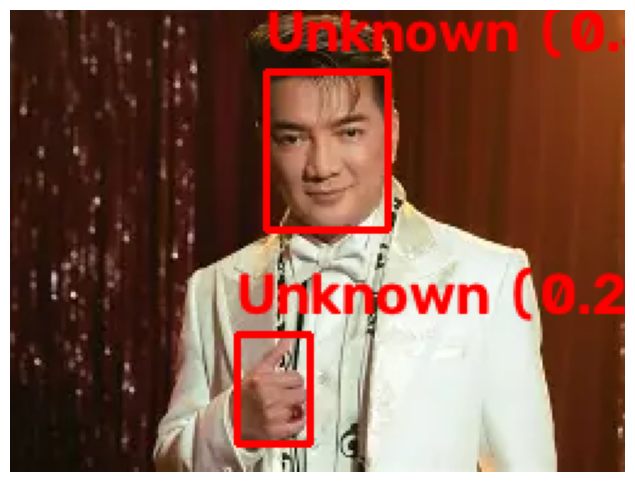

In [8]:
IMG_PATH = "../data/raw/image.png"
import pathlib
if not pathlib.Path(IMG_PATH).exists():
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/lena.jpg", IMG_PATH)
frame = cv2.imread(IMG_PATH)
assert frame is not None, f"Thiếu ảnh {IMG_PATH}"

dets = detect_faces_bgr(frame)
if not dets:
    print("Khong phat hien khuon mat nao trong anh.")
else:
    embs = embed_faces(frame, [d[0] for d in dets])
    for (x1, y1, x2, y2), vec in zip([d[0] for d in dets], embs):
        name, sim = match_face(vec, FACE_DB)
        label = f"Matched: {name} ({sim:.2f})" if sim > THRESHOLD else f"Unknown ({sim:.2f})"
        color = (0, 200, 0) if sim > THRESHOLD else (0, 0, 255)
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        cv2.putText(frame, label, (x1, y1 - 8), cv2.FONT_HERSHEY_SIMPLEX, .8, color, 2)

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); plt.axis("off")

## 5. Kết luận

- **FaceNet** tạo embedding (vector) mà **khuôn mặt giống nhau nằm gần nhau** trong không gian vector,
  không cần huấn luyện lại (transfer từ `vggface2`); chạy được realtime vì embedding chỉ 512 chiều.
- **MTCNN** làm bước phát hiện khuôn mặt, ổn định với góc nhìn/ánh sáng khác nhau.
- Ngưỡng **0.7** là mặc định của đề bài; trong thực tế nên tinh chỉnh ngưỡng theo bộ test riêng của mình
  (dễ sai khi ảnh mờ, góc nghiêng quá lớn, che khuất).
- Hạn chế: nhạy với độ phân giải nhỏ, người ngoài CSDL luôn "Unknown"; muốn tốt hơn có thể
  lưu nhiều embedding/người thay vì trung bình, thêm chống giả mạo (anti-spoofing),
  hoặc thay bằng mô hình ArcFace/Siamese.